In [1]:
!pip install -q shap

In [3]:
from google.colab import drive
drive.mount("/content/drive")



Mounted at /content/drive


In [4]:
DATA_PATH = "/content/drive/MyDrive/Research_Data/monitoring_visits_clean.csv"
OUT_DIR ="/content/drive/MyDrive/Research_Data/grant_risk_model"

In [5]:
import os, json, datetime, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, shap
from scipy import stats
from sklearn.base import BaseEstimator
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score)

warnings.filterwarnings("ignore")
os.makedirs(OUT_DIR, exist_ok=True)
SEED = 42


In [6]:
df = pd.read_csv(DATA_PATH)
data = df[df["grant_spent_lkr"].notna()].copy()

print("All visits:", len(df))
print("Visits with grant money data:", len(data))
print("Visits without household ID:", data["household_id"].isna().sum())


All visits: 649
Visits with grant money data: 233
Visits without household ID: 37


In [7]:
data["has_id"] = data["household_id"].notna().astype(int)
data["group_id"] = data["household_id"].fillna("UNK_" + data["source_uuid"])
data["refund"] = (
    data["refund_required"]
    .map({True: 1, False: 0, "True": 1, "False": 0})
    .fillna(0)
    .astype(int)
)
data = data.sort_values(["group_id", "month_index"]).reset_index(drop=True)

print("Groups (households + single visits):", data["group_id"].nunique())
print(
    "Refund visits:",
    data["refund"].sum(),
    "| refund groups:",
    data.loc[data["refund"] == 1, "group_id"].nunique(),
)


Groups (households + single visits): 77
Refund visits: 14 | refund groups: 4


In [8]:
FEATURES = [
    "spent_pct", "spend_rate", "spend_change", "total_change", "remaining_up",
    "bills_streak", "slow_use", "not_per_plan", "business_running", "profit",
    "borrowed_money", "revenue_mid_lkr", "problem_count", "record_keeping_level",
    "saved_amount_lkr", "has_history", "revenue_missing", "form_incomplete",
]


def to01(s):
    return s.map({True: 1, False: 0, "True": 1, "False": 0}).astype(float)


def streak(s):
    return s.groupby((s == 0).cumsum()).cumsum()


def make_features(visits):
    v = visits.sort_values(["group_id", "month_index"]).copy()
    v["grant_total"] = v["grant_spent_lkr"] + v["grant_remaining_lkr"]
    prev = v.groupby("group_id")[
        ["grant_total", "grant_spent_lkr", "grant_remaining_lkr"]
    ].shift()

    v["has_history"] = prev["grant_total"].notna().astype(int)
    v["total_change"] = (v["grant_total"] - prev["grant_total"]).fillna(0)
    v["spend_change"] = (v["grant_spent_lkr"] - prev["grant_spent_lkr"]).fillna(0)
    v["remaining_up"] = (v["grant_remaining_lkr"] > prev["grant_remaining_lkr"]).astype(
        int
    )
    v["spent_pct"] = (
        v["grant_spent_lkr"] / v["grant_total"].replace(0, np.nan)
    ).fillna(0)
    v["spend_rate"] = v["spent_pct"] / v["month_index"].clip(lower=1)
    v["slow_use"] = ((v["month_index"] >= 3) & (v["spent_pct"] < 0.5)).astype(int)

    unsettled = (
        v["grant_use_status"] == "Received, fully used, bills not settled"
    ).astype(int)
    v["bills_streak"] = unsettled.groupby(v["group_id"]).transform(streak)
    v["not_per_plan"] = (to01(v["grant_used_per_plan"]) == 0).astype(int)

    for c in ["business_running", "profit", "borrowed_money"]:
        v[c] = to01(v[c])
    v["revenue_missing"] = v["revenue_mid_lkr"].isna().astype(int)
    v["form_incomplete"] = (
        v[["profit", "borrowed_money", "problem_count", "record_keeping_level"]]
        .isna()
        .any(axis=1)
        .astype(int)
    )
    return v


feats = make_features(data)
feats[["group_id", "month_index"] + FEATURES].head()


,group_id,month_index,spent_pct,spend_rate,spend_change,total_change,remaining_up,bills_streak,slow_use,not_per_plan,business_running,profit,borrowed_money,revenue_mid_lkr,problem_count,record_keeping_level,saved_amount_lkr,has_history,revenue_missing,form_incomplete
0,HH-001,1,0.333333,0.333333,0.0,0.0,0,0,0,0,1.0,0.0,0.0,5000.0,0.0,1.0,0.0,0,0,0
1,HH-001,2,0.533333,0.266667,30000.0,0.0,0,0,0,0,1.0,0.0,0.0,NaN,0.0,NaN,0.0,1,1,1
2,HH-001,3,0.600000,0.200000,10000.0,0.0,0,0,0,0,1.0,0.0,0.0,NaN,0.0,0.0,0.0,1,1,0
3,HH-001,4,0.700000,0.175000,15000.0,0.0,0,0,0,0,1.0,1.0,0.0,5000.0,0.0,1.0,0.0,1,0,0
4,HH-001,6,0.733333,0.122222,5000.0,0.0,0,0,0,0,1.0,0.0,0.0,NaN,0.0,0.0,0.0,1,1,0


In [9]:
miss = (feats[FEATURES].isna().mean() * 100).round(1).sort_values(ascending=False)
print("Missing % per feature:")
print(miss[miss > 0])

has_rev = feats[feats["revenue_missing"] == 0]
no_rev = feats[feats["revenue_missing"] == 1]
for c in ["spent_pct", "business_running", "month_index"]:
    p = stats.mannwhitneyu(has_rev[c].dropna(), no_rev[c].dropna()).pvalue
    print(f"Revenue missing vs present - {c}: p = {p:.3f}")


Missing % per feature:
revenue_mid_lkr         39.1
record_keeping_level    13.3
profit                  10.7
problem_count           10.7
borrowed_money           9.0
saved_amount_lkr         0.4
dtype: float64
Revenue missing vs present - spent_pct: p = 0.882
Revenue missing vs present - business_running: p = 0.000
Revenue missing vs present - month_index: p = 0.166


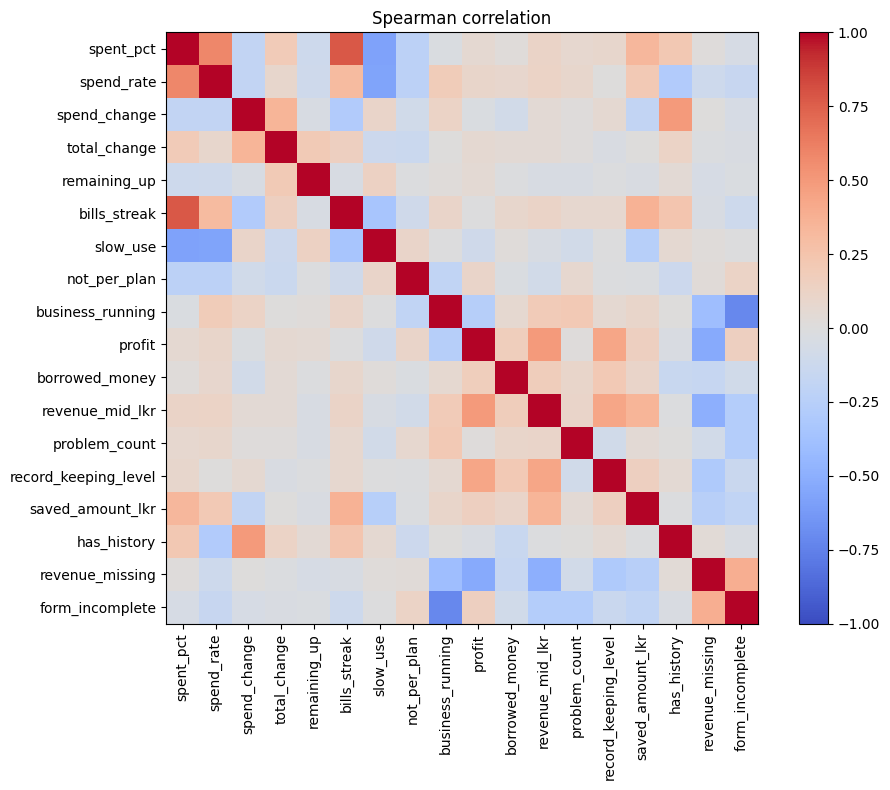

spent_pct           3.67
spend_change        3.47
total_change        3.19
business_running    3.12
profit              3.06
revenue_missing     2.59
form_incomplete     2.45
spend_rate          2.37
dtype: float64


In [10]:
num = feats[FEATURES].fillna(feats[FEATURES].median())
corr = num.corr(method="spearman")

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(FEATURES)), FEATURES, rotation=90)
plt.yticks(range(len(FEATURES)), FEATURES)
plt.colorbar()
plt.title("Spearman correlation")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/correlation.png", dpi=150)
plt.show()


def vif(X):
    out = {}
    for c in X.columns:
        others = X.drop(columns=c)
        r2 = LinearRegression().fit(others, X[c]).score(others, X[c])
        out[c] = round(1 / max(1 - r2, 1e-6), 2)
    return pd.Series(out).sort_values(ascending=False)


print(vif(num).head(8))


In [11]:
RULES = [
    ("total_changed", 3, "Grant total changed since last visit"),
    ("remaining_up", 3, "Remaining amount went up"),
    ("spent_but_stopped", 2, "Grant spent but business not running"),
    ("not_per_plan", 2, "Grant not used as per plan"),
    ("bills_unsettled", 1, "Bills not settled 2+ visits in a row"),
    ("slow_use", 1, "Less than 50% used after 3 months"),
]
MAX_POINTS = sum(w for _, w, _ in RULES)


def rule_hits(f):
    return pd.DataFrame(
        {
            "total_changed": (f["has_history"] == 1) & (f["total_change"] != 0),
            "remaining_up": f["remaining_up"] == 1,
            "spent_but_stopped": (f["spent_pct"] >= 0.5) & (f["business_running"] == 0),
            "not_per_plan": f["not_per_plan"] == 1,
            "bills_unsettled": f["bills_streak"] >= 2,
            "slow_use": f["slow_use"] == 1,
        },
        index=f.index,
    )


def rule_score(f):
    hits = rule_hits(f)
    return sum(hits[name] * w for name, w, _ in RULES) / MAX_POINTS


def rule_reasons(f):
    hits = rule_hits(f)
    return hits.apply(lambda r: [text for name, _, text in RULES if r[name]], axis=1)


feats["rule_score"] = rule_score(feats)
print(rule_hits(feats).sum())
print("Visits with at least one rule hit:", (feats["rule_score"] > 0).sum())


total_changed        22
remaining_up          1
spent_but_stopped    16
not_per_plan          4
bills_unsettled      51
slow_use             44
dtype: int64
Visits with at least one rule hit: 127


In [12]:
class RobustZ(BaseEstimator):
    def fit(self, X, y=None):
        self.med_ = np.median(X, axis=0)
        mad = np.median(np.abs(X - self.med_), axis=0) * 1.4826
        self.scale_ = np.where(mad == 0, X.std(axis=0) + 1e-9, mad)
        return self

    def score_samples(self, X):
        return -np.abs((X - self.med_) / self.scale_).mean(axis=1)


DEFAULTS = {
    "robust_z": {},
    "iforest": {"n_estimators": 300, "max_features": 1.0},
    "lof": {"n_neighbors": 20},
    "ocsvm": {"nu": 0.1, "gamma": "scale"},
}


def make_model(name="iforest", imputer="median", seed=SEED, **params):
    p = {**DEFAULTS[name], **params}
    imp = (
        SimpleImputer(strategy="median")
        if imputer == "median"
        else KNNImputer(n_neighbors=5)
    )
    if name == "robust_z":
        model = RobustZ()
    elif name == "iforest":
        model = IsolationForest(random_state=seed, **p)
    elif name == "lof":
        model = LocalOutlierFactor(novelty=True, **p)
    else:
        model = OneClassSVM(**p)
    return Pipeline([("imputer", imp), ("scaler", StandardScaler()), ("model", model)])


def unusualness(pipe, X):
    return -pipe.score_samples(X[FEATURES])


def to_percentile(train_raw, raw):
    return np.searchsorted(np.sort(train_raw), raw, side="right") / len(train_raw)


def combine(rule, model, w=0.5):
    if w == "max":
        return np.maximum(rule, model)
    return w * rule + (1 - w) * model


In [14]:
INJECT_TYPES = [
    "total_jump", "remaining_up", "stopped_after_spend", "spend_no_income", "cash_mismatch",
]


def inject(rows, rng):
    out = rows.copy()
    start = rng.integers(len(INJECT_TYPES))
    types = [INJECT_TYPES[(start + i) % len(INJECT_TYPES)] for i in range(len(out))]
    for idx, t in zip(out.index, types):
        m = max(out.at[idx, "month_index"], 1)
        if t == "total_jump":
            change = {"total_change": rng.choice([25000, 50000, 75000, 100000]),
                      "has_history": 1}
        elif t == "remaining_up":
            change = {"remaining_up": 1, "has_history": 1,
                      "total_change": rng.choice([20000, 40000, 60000])}
        elif t == "stopped_after_spend":
            change = {"spent_pct": 1.0, "spend_rate": 1 / m, "business_running": 0,
                      "profit": 0, "revenue_mid_lkr": 5000}
        elif t == "spend_no_income":
            change = {"spent_pct": 1.0, "spend_rate": 1 / m, "spend_change": 150000,
                      "revenue_mid_lkr": 5000, "profit": 0, "record_keeping_level": 0,
                      "saved_amount_lkr": 0, "business_running": 1}
        else:
            change = {"revenue_mid_lkr": 35000, "profit": 0, "borrowed_money": 1,
                      "saved_amount_lkr": rng.choice([30000, 40000, 50000]),
                      "problem_count": 4}
        for col, val in change.items():
            out.at[idx, col] = val
    out["type"] = types
    out["label"] = 1
    out["rule_score"] = rule_score(out)
    return out


In [15]:
def run_cv(
    feats,
    n_rep=10,
    k=5,
    seed=SEED,
    inject_share=0.15,
    name="iforest",
    imputer="median",
    **params,
):
    groups = feats["group_id"].unique()
    folds_out = []
    for rep in range(n_rep):
        rng = np.random.default_rng(seed + rep)
        split = np.array_split(rng.permutation(groups), k)
        for fold, test_groups in enumerate(split):
            in_test = feats["group_id"].isin(test_groups)
            train = feats[~in_test & (feats["refund"] == 0)]
            normal = feats[in_test & (feats["refund"] == 0)].assign(
                type="normal", label=0
            )
            refund = feats[in_test & (feats["refund"] == 1)].assign(
                type="refund", label=1
            )
            n_inj = max(5, round(inject_share * len(normal)))
            picked = normal.sample(
                n_inj,
                replace=n_inj > len(normal),
                random_state=int(rng.integers(10**9)),
            )
            test = pd.concat([normal, inject(picked, rng)], ignore_index=True)

            pipe = make_model(name, imputer, seed + rep, **params).fit(train[FEATURES])
            train_raw = unusualness(pipe, train)
            test["model_score"] = to_percentile(train_raw, unusualness(pipe, test))
            if len(refund):
                refund["model_score"] = to_percentile(
                    train_raw, unusualness(pipe, refund)
                )
            folds_out.append(
                {
                    "rep": rep,
                    "fold": fold,
                    "test": test,
                    "refund": refund,
                    "train_rule": train["rule_score"].values,
                    "train_model": to_percentile(train_raw, train_raw),
                    "n_train": len(train),
                }
            )
    return folds_out


def evaluate(folds_out, score="hybrid", w=0.5, top=0.10):
    rows = []
    for f in folds_out:
        t = f["test"]
        if score == "rule":
            s, s_train = t["rule_score"], f["train_rule"]
        elif score == "model":
            s, s_train = t["model_score"], f["train_model"]
        else:
            s, s_train = combine(t["rule_score"], t["model_score"], w), combine(
                f["train_rule"], f["train_model"], w
            )
        flag = s >= np.quantile(s_train, 1 - top)
        row = {
            "rep": f["rep"],
            "fold": f["fold"],
            "roc_auc": roc_auc_score(t["label"], s),
            "pr_auc": average_precision_score(t["label"], s),
            "precision": precision_score(t["label"], flag, zero_division=0),
            "recall": recall_score(t["label"], flag),
            "f1": f1_score(t["label"], flag),
        }
        for typ in INJECT_TYPES:
            row[f"recall_{typ}"] = flag[t["type"] == typ].mean()
        rows.append(row)
    return pd.DataFrame(rows)


def summary(res, cols=("roc_auc", "pr_auc", "precision", "recall", "f1")):
    return res[list(cols)].agg(["mean", "std"]).T.round(3)


           mean    std
ocsvm     0.922  0.051
lof       0.909  0.061
iforest   0.845  0.068
robust_z  0.832  0.084


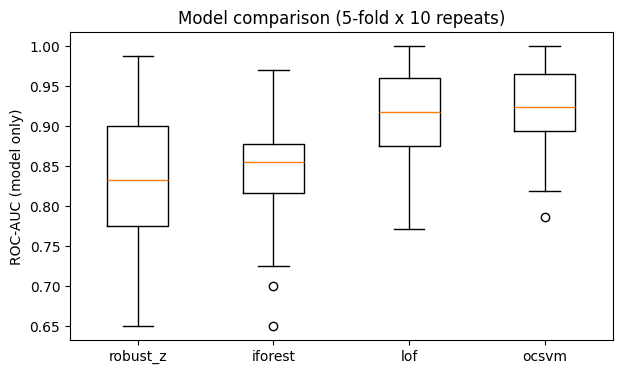

Best model: ocsvm


In [16]:
DEV_SEED = 1000
MODELS = ["robust_z", "iforest", "lof", "ocsvm"]
dev_runs = {name: run_cv(feats, seed=DEV_SEED, name=name) for name in MODELS}

model_auc = pd.DataFrame(
    {n: evaluate(r, score="model")["roc_auc"] for n, r in dev_runs.items()}
)
print(model_auc.agg(["mean", "std"]).T.round(3).sort_values("mean", ascending=False))

plt.figure(figsize=(7, 4))
plt.boxplot(model_auc.values)
plt.xticks(range(1, len(MODELS) + 1), MODELS)
plt.ylabel("ROC-AUC (model only)")
plt.title("Model comparison (5-fold x 10 repeats)")
plt.savefig(f"{OUT_DIR}/model_comparison.png", dpi=150)
plt.show()

BEST = model_auc.mean().idxmax()
print("Best model:", BEST)


In [17]:
def corrected_ttest(a, b, test_train_ratio=0.25):
    d = np.asarray(a) - np.asarray(b)
    n = len(d)
    t = d.mean() / np.sqrt((1 / n + test_train_ratio) * d.var(ddof=1))
    return 2 * stats.t.sf(abs(t), n - 1)


for other in model_auc.columns.drop(BEST):
    p_w = stats.wilcoxon(model_auc[BEST], model_auc[other]).pvalue
    p_t = corrected_ttest(model_auc[BEST], model_auc[other])
    print(f"{BEST} vs {other}: Wilcoxon p = {p_w:.4f} | corrected t-test p = {p_t:.4f}")


ocsvm vs robust_z: Wilcoxon p = 0.0000 | corrected t-test p = 0.0446
ocsvm vs iforest: Wilcoxon p = 0.0000 | corrected t-test p = 0.0195
ocsvm vs lof: Wilcoxon p = 0.0279 | corrected t-test p = 0.5413


In [18]:
auc_median = model_auc[BEST]
auc_knn = evaluate(
    run_cv(feats, seed=DEV_SEED, name=BEST, imputer="knn"), score="model"
)["roc_auc"]
p = stats.wilcoxon(auc_median, auc_knn).pvalue
print(f"Median imputer AUC: {auc_median.mean():.3f}")
print(f"KNN imputer AUC:    {auc_knn.mean():.3f} (Wilcoxon p = {p:.4f})")
IMPUTER = "knn" if (auc_knn.mean() > auc_median.mean() and p < 0.05) else "median"

GRIDS = {
    "robust_z": [{}],
    "iforest": [
        {"n_estimators": n, "max_features": f} for n in [100, 300] for f in [0.5, 1.0]
    ],
    "lof": [{"n_neighbors": k} for k in [10, 20, 35]],
    "ocsvm": [
        {"nu": nu, "gamma": g} for nu in [0.05, 0.1, 0.2] for g in [0.02, "scale", 0.1]
    ],
}
grid = []
for params in GRIDS[BEST]:
    r = run_cv(feats, n_rep=5, seed=DEV_SEED, name=BEST, imputer=IMPUTER, **params)
    grid.append({**params, "roc_auc": evaluate(r, score="model")["roc_auc"].mean()})
grid = pd.DataFrame(grid)
print(grid.round(3))

BEST_PARAMS = GRIDS[BEST][int(grid["roc_auc"].idxmax())]

dev_best = run_cv(feats, seed=DEV_SEED, name=BEST, imputer=IMPUTER, **BEST_PARAMS)
w_table = pd.DataFrame(
    {str(w): summary(evaluate(dev_best, w=w))["mean"] for w in [0.3, 0.5, 0.7]}
).T
print(w_table)
W = [0.3, 0.5, 0.7][int(np.argmax(w_table["pr_auc"].values))]
TOP = 0.10
print("Chosen model:", BEST, BEST_PARAMS)
print("Imputer:", IMPUTER, "| rule weight:", W)


Median imputer AUC: 0.922
KNN imputer AUC:    0.922 (Wilcoxon p = 0.8186)
     nu  gamma  roc_auc
0  0.05   0.02    0.911
1  0.05  scale    0.879
2  0.05    0.1    0.837
3  0.10   0.02    0.913
4  0.10  scale    0.919
5  0.10    0.1    0.836
6  0.20   0.02    0.912
7  0.20  scale    0.934
8  0.20    0.1    0.932
     roc_auc  pr_auc  precision  recall     f1
0.3    0.939   0.709      0.467   0.975  0.624
0.5    0.929   0.682      0.483   0.826  0.598
0.7    0.905   0.646      0.521   0.715  0.586
Chosen model: ocsvm {'nu': 0.2, 'gamma': 'scale'}
Imputer: median | rule weight: 0.3


In [19]:
final_cv = run_cv(feats, seed=SEED, name=BEST, imputer=IMPUTER, **BEST_PARAMS)

In [20]:
a_rule = evaluate(final_cv, score="rule")
a_model = evaluate(final_cv, score="model")
a_hyb = evaluate(final_cv, score="hybrid", w=W)

ablation = pd.DataFrame(
    {
        "Rules only": summary(a_rule)["mean"],
        "Model only": summary(a_model)["mean"],
        "Rules + Model": summary(a_hyb)["mean"],
    }
).T
print(ablation)
for metric in ["roc_auc", "pr_auc"]:
    p1 = stats.wilcoxon(a_hyb[metric], a_rule[metric]).pvalue
    p2 = stats.wilcoxon(a_hyb[metric], a_model[metric]).pvalue
    print(f"{metric}: hybrid vs rules p = {p1:.4f} | hybrid vs model p = {p2:.4f}")


               roc_auc  pr_auc  precision  recall     f1
Rules only       0.778   0.485      0.460   0.579  0.481
Model only       0.939   0.675      0.450   0.963  0.604
Rules + Model    0.948   0.733      0.472   0.986  0.629
roc_auc: hybrid vs rules p = 0.0000 | hybrid vs model p = 0.0178
pr_auc: hybrid vs rules p = 0.0000 | hybrid vs model p = 0.0011


In [21]:
weights = pd.DataFrame(
    {str(w): summary(evaluate(final_cv, w=w))["mean"] for w in [0.3, 0.5, 0.7, "max"]}
).T
print("Rule weight (rule share of the final score):")
print(weights)

cutoffs = pd.DataFrame(
    {
        f"top {int(t * 100)}%": summary(evaluate(final_cv, w=W, top=t))["mean"]
        for t in [0.05, 0.10, 0.15]
    }
).T
print("High-risk cut-off:")
print(cutoffs)


Rule weight (rule share of the final score):
     roc_auc  pr_auc  precision  recall     f1
0.3    0.948   0.733      0.472   0.986  0.629
0.5    0.938   0.707      0.490   0.864  0.610
0.7    0.920   0.680      0.552   0.760  0.616
max    0.940   0.675      0.450   0.963  0.604
High-risk cut-off:
         roc_auc  pr_auc  precision  recall     f1
top 5%     0.948   0.733      0.656   0.675  0.624
top 10%    0.948   0.733      0.472   0.986  0.629
top 15%    0.948   0.733      0.390   0.986  0.551


In [22]:
res = evaluate(final_cv, w=W, top=TOP)
print(summary(res))

rep0 = pd.concat([f["test"] for f in final_cv if f["rep"] == 0], ignore_index=True)
rep0["risk"] = combine(rep0["rule_score"], rep0["model_score"], W)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    s = rep0.sample(len(rep0), replace=True, random_state=int(rng.integers(10**9)))
    if s["label"].nunique() == 2:
        boot.append(roc_auc_score(s["label"], s["risk"]))
pooled = roc_auc_score(rep0["label"], rep0["risk"])
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
print(f"Pooled ROC-AUC {pooled:.3f} (95% CI {ci_low:.3f} - {ci_high:.3f})")

per_type = res[[f"recall_{t}" for t in INJECT_TYPES]].mean().round(3)
print("Recall per problem type:")
print(per_type)


            mean    std
roc_auc    0.948  0.034
pr_auc     0.733  0.147
precision  0.472  0.123
recall     0.986  0.043
f1         0.629  0.108
Pooled ROC-AUC 0.933 (95% CI 0.889 - 0.966)
Recall per problem type:
recall_total_jump             0.93
recall_remaining_up           0.99
recall_stopped_after_spend    1.00
recall_spend_no_income        1.00
recall_cash_mismatch          1.00
dtype: float64


In [23]:
normal0 = rep0[rep0["type"] == "normal"]
refund0 = pd.concat([f["refund"] for f in final_cv if f["rep"] == 0], ignore_index=True)
refund0["risk"] = combine(refund0["rule_score"], refund0["model_score"], W)

for col, side in [("risk", "greater"), ("spent_pct", "less")]:
    a, b = refund0[col], normal0[col]
    p = stats.mannwhitneyu(a, b, alternative=side).pvalue
    print(f"{col}: refund median {a.median():.2f} | normal median {b.median():.2f} | p = {p:.4f}")

print("Refund visits caught by the slow-use rule:", refund0["slow_use"].sum(), "of", len(refund0))


risk: refund median 0.37 | normal median 0.39 | p = 0.6512
spent_pct: refund median 0.47 | normal median 0.87 | p = 0.0010
Refund visits caught by the slow-use rule: 4 of 14


In [24]:
train_all = feats[feats["refund"] == 0]
final_pipe = make_model(BEST, IMPUTER, **BEST_PARAMS).fit(train_all[FEATURES])

train_raw = unusualness(final_pipe, train_all)
feats["model_score"] = to_percentile(train_raw, unusualness(final_pipe, feats))
feats["risk"] = combine(feats["rule_score"], feats["model_score"], W)

train_risk = feats.loc[feats["refund"] == 0, "risk"]
THRESHOLDS = {
    "medium": float(np.quantile(train_risk, 0.70)),
    "high": float(np.quantile(train_risk, 1 - TOP)),
}
feats["level"] = np.select(
    [feats["risk"] >= THRESHOLDS["high"], feats["risk"] >= THRESHOLDS["medium"]],
    ["High", "Medium"],
    "Low",
)
print("Thresholds:", {k: round(v, 3) for k, v in THRESHOLDS.items()})
print(feats["level"].value_counts())


Thresholds: {'medium': 0.513, 'high': 0.649}
level
Low       164
Medium     44
High       25
Name: count, dtype: int64


In [25]:
rng = np.random.default_rng(SEED)
sub_scores = []
for s in range(10):
    part = train_all.sample(frac=0.8, random_state=int(rng.integers(10**9)))
    p = make_model(BEST, IMPUTER, seed=s, **BEST_PARAMS).fit(part[FEATURES])
    raw = unusualness(p, part)
    sub_scores.append(to_percentile(raw, unusualness(p, feats)))


def top_set(scores, share=0.10):
    return set(np.argsort(-np.asarray(scores))[: int(len(scores) * share)])


def jaccard(a, b):
    return len(top_set(a) & top_set(b)) / len(top_set(a) | top_set(b))


jac_m, jac_r, tau_m = [], [], []
for i in range(10):
    for j in range(i + 1, 10):
        a, b = sub_scores[i], sub_scores[j]
        jac_m.append(jaccard(a, b))
        ra = combine(feats["rule_score"], a, W)
        rb = combine(feats["rule_score"], b, W)
        jac_r.append(jaccard(ra, rb))
        tau_m.append(stats.kendalltau(a, b).statistic)

print(f"Top-10% overlap (Jaccard), model only: {np.mean(jac_m):.3f}")
print(f"Top-10% overlap (Jaccard), final risk: {np.mean(jac_r):.3f}")
print(f"Ranking agreement (Kendall tau), model only: {np.mean(tau_m):.3f}")


Top-10% overlap (Jaccard), model only: 0.647
Top-10% overlap (Jaccard), final risk: 0.670
Ranking agreement (Kendall tau), model only: 0.871


revenue_mid_lkr         0.181
slow_use                0.168
record_keeping_level    0.166
business_running        0.161
borrowed_money          0.119
spend_rate              0.104
problem_count           0.103
not_per_plan            0.101
dtype: float64


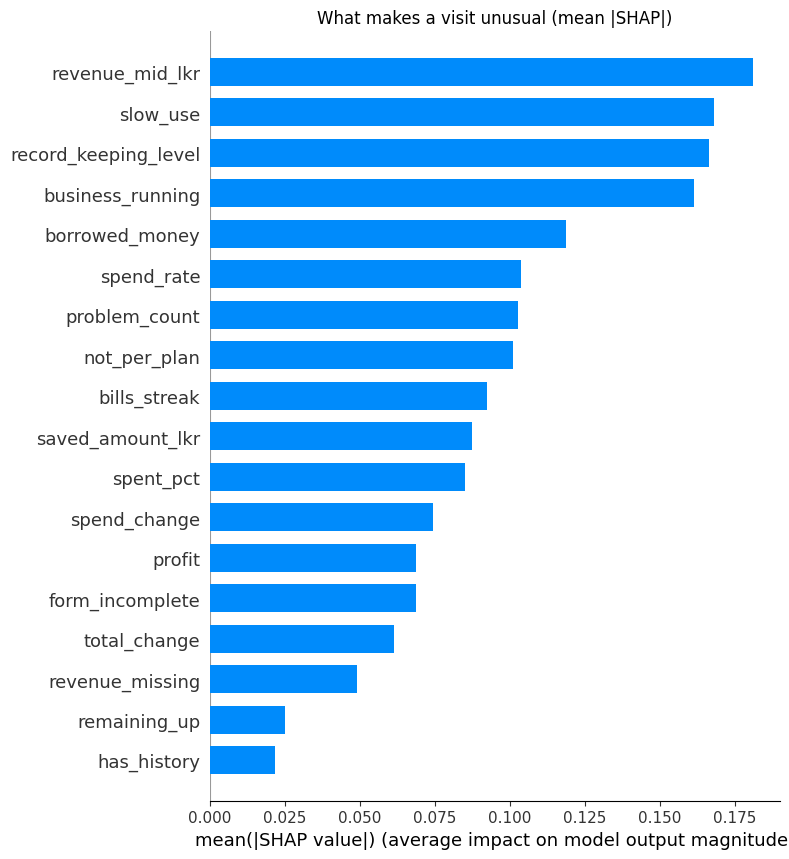

Rules vs model agreement: Spearman rho = 0.46, p = 0.0000


In [26]:
np.random.seed(SEED)
X_t = final_pipe[:-1].transform(feats[FEATURES])
background = shap.kmeans(final_pipe[:-1].transform(train_all[FEATURES]), 20)
explainer = shap.KernelExplainer(
    lambda X: -final_pipe.named_steps["model"].score_samples(X), background
)
shap_values = explainer.shap_values(X_t, nsamples=200, silent=True)

importance = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values(
    ascending=False
)
print(importance.head(8).round(3))

shap.summary_plot(
    shap_values, pd.DataFrame(X_t, columns=FEATURES), plot_type="bar", show=False
)
plt.title("What makes a visit unusual (mean |SHAP|)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/shap_importance.png", dpi=150)
plt.show()

rho, p = stats.spearmanr(feats["rule_score"], feats["model_score"])
print(f"Rules vs model agreement: Spearman rho = {rho:.2f}, p = {p:.4f}")


In [27]:
oof = pd.concat([normal0, refund0], ignore_index=True)
oof["high"] = (
    oof["risk"] >= np.quantile(feats.loc[feats["refund"] == 0, "risk"], 1 - TOP)
).astype(int)
hh = oof.groupby("group_id").agg(
    risk=("risk", "mean"),
    high=("high", "max"),
    gender=("beneficiary_gender", "first"),
    female_headed=("female_headed", "first"),
    district=("district", "first"),
)

for col in ["gender", "female_headed"]:
    g = hh.dropna(subset=[col])
    a, b = [grp["risk"] for _, grp in g.groupby(col)]
    medians = g.groupby(col)["risk"].median().round(2).to_dict()
    print(f"{col}: medians {medians} | Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.3f}")

d = hh[hh["district"].map(hh["district"].value_counts()) >= 5]
groups = [grp["risk"] for _, grp in d.groupby("district")]
print(f"district: Kruskal-Wallis p = {stats.kruskal(*groups).pvalue:.3f}")

known = hh.dropna(subset=["gender"])
table = pd.crosstab(known["gender"], known["high"])
print(f"High flag by gender: Fisher exact p = {stats.fisher_exact(table).pvalue:.3f}")


gender: medians {'Female': 0.3, 'Male': 0.41} | Mann-Whitney p = 0.180
female_headed: medians {False: 0.4, True: 0.32} | Mann-Whitney p = 0.483
district: Kruskal-Wallis p = 0.067
High flag by gender: Fisher exact p = 0.295


{
  "household_id": "HH_EXAMPLE",
  "risk_score": 0.9,
  "risk_level": "High",
  "rule_score": 0.67,
  "model_score": 1.0,
  "flags": [
    "Grant total changed since last visit",
    "Remaining amount went up",
    "Grant spent but business not running"
  ],
  "top_factors": [
    "remaining_up",
    "borrowed_money",
    "total_change"
  ],
  "action": "Officer review"
}


In [30]:
versions = {
    "scikit-learn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "joblib": joblib.__version__,
    "shap": shap.__version__,
}
bundle = {
    "pipeline": final_pipe,
    "model_name": BEST,
    "features": FEATURES,
    "shap_background": background.data,
    "train_scores": np.sort(train_raw),
    "rule_weight": W,
    "thresholds": THRESHOLDS,
    "rules": RULES,
    "max_points": MAX_POINTS,
    "versions": versions,
    "trained_on": len(train_all),
    "created": datetime.date.today().isoformat(),
}
joblib.dump(bundle, f"{OUT_DIR}/grant_risk.joblib")

results = {
    "model": BEST,
    "params": BEST_PARAMS,
    "imputer": IMPUTER,
    "rule_weight": W,
    "thresholds": THRESHOLDS,
    "cv_summary": summary(res)["mean"].to_dict(),
    "pooled_roc_auc": float(pooled),
    "roc_auc_95ci": [float(ci_low), float(ci_high)],
    "recall_per_type": per_type.to_dict(),
}
with open(f"{OUT_DIR}/results.json", "w") as fh:
    json.dump(results, fh, indent=2, default=float)
with open(f"{OUT_DIR}/versions.txt", "w") as fh:
    for k, v in versions.items():
        fh.write(f"{k}=={v}\n")

check = joblib.load(f"{OUT_DIR}/grant_risk.joblib")
print("Saved and reloaded OK:", list(check.keys()))
print(open(f"{OUT_DIR}/versions.txt").read())


Saved and reloaded OK: ['pipeline', 'model_name', 'features', 'shap_background', 'train_scores', 'rule_weight', 'thresholds', 'rules', 'max_points', 'versions', 'trained_on', 'created']
scikit-learn==1.6.1
numpy==2.1.3
pandas==2.2.3
joblib==1.6.0
shap==0.54.1

